# Weather Prediction and Model Comparison

The aim of this notebook is to explore weather patterns, dependencies of different elements with temperature, and observing extreme weather events. After data analysis, ML is used to perform prediction and then the performance of models are compared against each other and an established baseline.


Dataset Name and link: European Cities Weather Prediction Dataset ( https://www.kaggle.com/datasets/orvile/european-cities-weather-prediction-dataset?select=weather_prediction_dataset.csv )

## Data Loading

Importing all the relevant libraries

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt
from plotly.subplots import make_subplots
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, pacf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings("ignore")
import os

Loading the dataset

In [2]:
df = pd.read_csv("C:/Users/abdul/Downloads/weather_prediction_dataset.csv")

In [3]:
df.head()

,DATE,MONTH,BASEL_cloud_cover,BASEL_humidity,BASEL_pressure,BASEL_global_radiation,BASEL_precipitation,BASEL_sunshine,BASEL_temp_mean,BASEL_temp_min,...,STOCKHOLM_temp_min,STOCKHOLM_temp_max,TOURS_wind_speed,TOURS_humidity,TOURS_pressure,TOURS_global_radiation,TOURS_precipitation,TOURS_temp_mean,TOURS_temp_min,TOURS_temp_max
0,20000101,1,8,0.89,1.0286,0.20,0.03,0.0,2.9,1.6,...,-9.3,0.7,1.6,0.97,1.0275,0.25,0.04,8.5,7.2,9.8
1,20000102,1,8,0.87,1.0318,0.25,0.00,0.0,3.6,2.7,...,0.5,2.0,2.0,0.99,1.0293,0.17,0.16,7.9,6.6,9.2
2,20000103,1,5,0.81,1.0314,0.50,0.00,3.7,2.2,0.1,...,-1.0,2.8,3.4,0.91,1.0267,0.27,0.00,8.1,6.6,9.6
3,20000104,1,7,0.79,1.0262,0.63,0.35,6.9,3.9,0.5,...,2.5,4.6,4.9,0.95,1.0222,0.11,0.44,8.6,6.4,10.8
4,20000105,1,5,0.90,1.0246,0.51,0.07,3.7,6.0,3.8,...,-1.8,2.9,3.6,0.95,1.0209,0.39,0.04,8.0,6.4,9.5


Since, we are only concerned with investigating the city "Tours" here, we will drop all other columns.

In [4]:
df = df[['DATE','MONTH','TOURS_wind_speed','TOURS_humidity','TOURS_pressure','TOURS_global_radiation',
           'TOURS_precipitation','TOURS_temp_mean','TOURS_temp_min','TOURS_temp_max']]

In [5]:
#Converting the DATE column to YYYY-MM-DD format
df['DATE'] = pd.to_datetime(df['DATE'], format='%Y%m%d')

In [6]:
#Creating the column Year from the column DATE
df['Year'] = df['DATE'].dt.year

In [7]:
#Counting the values associated with each year
df['Year'].value_counts()

Year
2000    366
2004    366
2008    366
2001    365
2002    365
2003    365
2005    365
2006    365
2007    365
2009    365
2010      1
Name: count, dtype: int64

Since 2010 only has 1 entry, we will discard it.

In [8]:
df = df[df['Year'].between(2000, 2009)]

Creating the column of Diurnal temperature to observe the variation between max and min temperautes. According to wikipedia: In meteorology, diurnal temperature variation is the variation between a high air temperature and a low temperature that occurs during the same day.

In [9]:
df["TOURS_diurnal_temp"] = df["TOURS_temp_max"] - df["TOURS_temp_min"]

## Exploratory Data Analysis

In [10]:
os.makedirs("charts", exist_ok=True)

In [11]:
temp_over_years = px.line(df, x="DATE", y="TOURS_temp_mean", title='Mean temperature 2000-2009 in Tours',color_discrete_sequence=["red"])
temp_over_years.show()

temp_over_years.write_image("charts/Mean temperature 2000-2009 in Tours.png")

From this chart we observe high peaks in 2003, 2006 and low peaks in 2003, 2009.

In [12]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=df["DATE"], y=df["TOURS_temp_mean"], name="Mean", line=dict(color='orange')))

fig.add_trace(go.Scatter(x=df["DATE"], y=df["TOURS_temp_min"], name="Minimum", line=dict(color='royalblue')))

fig.add_trace(go.Scatter(x=df["DATE"], y=df["TOURS_temp_max"], name="Maximum", line=dict(color='firebrick')))

fig.add_trace(go.Scatter(x=df["DATE"], y=df["TOURS_diurnal_temp"], name="Diurnal", line=dict(color='green')))

fig.update_layout(title=dict(text="Mean,Maximum,Minimum and Diurnal temperatures in Tours 2000-2009"))

fig.show()

fig.write_image("charts/Mean,Maximum,Minimum and Diurnal temperatures in Tours 2000-2009.png")

In [13]:
meantemp_by_year = df.groupby('Year')['TOURS_temp_mean'].mean().reset_index()

meantemp_by_year_fig = px.line(meantemp_by_year, x='Year', y='TOURS_temp_mean',
                                     title='Yearly mean temperature 2000-2009',color_discrete_sequence=["red"])

meantemp_by_year_fig.show()

meantemp_by_year_fig.write_image("charts/Yearly mean temperature 2000-2009.png")

In [14]:
precipitation_by_year = df.groupby('Year')['TOURS_precipitation'].mean().reset_index()

precipitation_by_year_fig = px.line(precipitation_by_year, x='Year', y='TOURS_precipitation',
                                     title='Average precipitation 2000-2009',color_discrete_sequence=["red"])

precipitation_by_year_fig.show()

precipitation_by_year_fig.write_image("charts/Average precipitation 2000-2009.png")

In [15]:
humidity_by_year = df.groupby('Year')['TOURS_humidity'].mean().reset_index()

humidity_by_year_fig = px.line(humidity_by_year, x='Year', y='TOURS_humidity',
                                     title='Average humidity 2000-2009',color_discrete_sequence=["red"])

humidity_by_year_fig.show()

humidity_by_year_fig.write_image("charts/Average humidity 2000-2009.png")

In [98]:
#Isolating the maximum temperatures that have been observed during 2000-2009, to see any heatwave type scenarios.

highest_temp = df.sort_values(by='TOURS_temp_mean', ascending=False)

highest_temp.head(10)

,DATE,MONTH,TOURS_wind_speed,TOURS_humidity,TOURS_pressure,TOURS_global_radiation,TOURS_precipitation,TOURS_temp_mean,TOURS_temp_min,TOURS_temp_max,Year,TOURS_diurnal_temp
1317,2003-08-10,8,2.6,0.37,1.0144,2.68,0.00,31.2,22.6,39.8,2003,17.2
1316,2003-08-09,8,2.9,0.44,1.0160,2.73,0.00,31.0,22.6,39.3,2003,16.7
1312,2003-08-05,8,2.8,0.46,1.0189,2.66,0.00,30.8,22.2,39.3,2003,17.1
1313,2003-08-06,8,2.1,0.48,1.0185,2.71,0.00,30.2,20.7,39.7,2003,19.0
1314,2003-08-07,8,2.5,0.57,1.0175,2.66,0.00,30.0,22.0,37.9,2003,15.9
1311,2003-08-04,8,3.8,0.44,1.0189,2.89,0.00,29.4,20.8,38.0,2003,17.2
1318,2003-08-11,8,2.0,0.53,1.0170,2.54,0.00,29.2,21.4,37.0,2003,15.6
1315,2003-08-08,8,2.8,0.56,1.0164,2.59,0.00,29.2,20.5,38.0,2003,17.5
2398,2006-07-26,7,3.1,0.46,1.0142,2.82,0.18,29.0,20.7,37.3,2006,16.6
1319,2003-08-12,8,2.5,0.62,1.0196,2.61,0.00,29.0,20.9,37.1,2003,16.2


As per the dataframe, the major temperature spikes occur in the 2003, specifically in August. These can be attributed to the 2003 European Heatwave that also affected France.

In [16]:
df_2003 = df[df['Year'] == 2003]

fig_2003 = px.line(df_2003, x='DATE', y='TOURS_temp_mean', title="Mean Temperature in 2003",color_discrete_sequence=["red"])
fig_2003.show()

fig_2003.write_image("charts/Mean Temperature in 2003.png")

In [17]:
fig_2003_temp_prec_humi = go.Figure()

fig_2003_temp_prec_humi.add_trace(go.Scatter(x=df_2003['DATE'], y=df_2003['TOURS_temp_mean'], name="Mean Temperature",
                                             line=dict(color='blue')))

fig_2003_temp_prec_humi.add_trace(go.Scatter(x=df_2003['DATE'], y=df_2003['TOURS_precipitation'], name="Precipitation",
                                             line=dict(color='red')))

fig_2003_temp_prec_humi.add_trace(go.Scatter(x=df_2003['DATE'], y=df_2003['TOURS_humidity'], name="Humidity",
                                             line=dict(color='green')))

fig_2003_temp_prec_humi.update_layout(title=dict(text='Comparison of Temperature, Precipitation and Humidity in 2003'))

fig_2003_temp_prec_humi.show()

fig_2003_temp_prec_humi.write_image("charts/Comparison of Temperature, Precipitation and Humidity in 2003.png")

In [18]:
df_temp = df[df['MONTH'] == 8]
df_august = df_temp.groupby('Year')['TOURS_temp_mean'].mean().reset_index()

fig_aug = px.line(df_august, x='Year', y='TOURS_temp_mean', title="Mean Temperature in August",color_discrete_sequence=["red"])
fig_aug.show()

fig_aug.write_image("charts/Mean Temperature in August.png")

In [102]:
##Isolating the minimum temperatures that have been observed during 2000-2009, to see any abnormalities.


lowest_temp = df.sort_values(by='TOURS_temp_mean', ascending=True)

lowest_temp.head(10)

,DATE,MONTH,TOURS_wind_speed,TOURS_humidity,TOURS_pressure,TOURS_global_radiation,TOURS_precipitation,TOURS_temp_mean,TOURS_temp_min,TOURS_temp_max,Year,TOURS_diurnal_temp
3294,2009-01-07,1,2.8,0.71,1.0239,0.78,0.00,-6.2,-13.0,0.7,2009,13.7
1104,2003-01-09,1,4.5,0.77,1.0152,0.61,0.00,-5.6,-8.0,-3.1,2003,4.9
3296,2009-01-09,1,2.1,0.80,1.0267,0.74,0.00,-5.0,-9.0,-1.0,2009,8.0
3293,2009-01-06,1,4.0,0.82,1.0210,0.66,0.00,-4.9,-8.2,-1.6,2009,6.6
2189,2005-12-29,12,2.2,0.93,1.0186,0.24,0.00,-4.8,-7.8,-1.8,2005,6.0
3640,2009-12-19,12,2.4,0.90,1.0122,0.29,0.02,-4.5,-9.1,0.2,2009,9.3
3292,2009-01-05,1,2.0,0.92,1.0181,0.18,0.16,-4.4,-6.9,-1.9,2009,5.0
1103,2003-01-08,1,7.2,0.78,1.0096,0.53,0.00,-4.3,-5.6,-3.0,2003,2.6
1106,2003-01-11,1,6.2,0.75,1.0298,0.49,0.00,-4.2,-7.1,-1.3,2003,5.8
2909,2007-12-19,12,3.6,0.86,1.0341,0.64,0.00,-3.8,-5.6,-2.0,2007,3.6


As per the dataframe, the major temperature dips occur in the 2009 that can be attributed to the unprecedented cold spell and significant snowfall during the months of December 2009-March 2010 in europe. We observe some extremities in 2003 as well. According to the Le Monde's article "2003 en France : une année météorologique marquée par les extrêmes", in 2003 the months of January, February, and October were colder than usual.

In [19]:
df_2009 = df[df['Year'] == 2009]

fig_2009_temp_prec_humi = go.Figure()

fig_2009_temp_prec_humi.add_trace(go.Scatter(x=df_2009['DATE'], y=df_2009['TOURS_temp_mean'], name="Mean Temperature",
                                             line=dict(color='blue')))

fig_2009_temp_prec_humi.add_trace(go.Scatter(x=df_2009['DATE'], y=df_2009['TOURS_precipitation'], name="Precipitation",
                                             line=dict(color='red')))

fig_2009_temp_prec_humi.add_trace(go.Scatter(x=df_2009['DATE'], y=df_2009['TOURS_humidity'], name="Humidity",
                                             line=dict(color='green')))

fig_2009_temp_prec_humi.update_layout(title=dict(text='Comparison of Temperature, Precipitation and Humidity in 2009'))

fig_2009_temp_prec_humi.show()

fig_2009_temp_prec_humi.write_image("charts/Comparison of Temperature, Precipitation and Humidity in 2009.png")

In [20]:
df_monthly_temp = df.groupby('MONTH')['TOURS_temp_mean'].mean().reset_index()

fig_jan = px.line(df_monthly_temp, x='MONTH', y='TOURS_temp_mean', title="Monthly Mean Temperature in Tours",color_discrete_sequence=["red"])
fig_jan.show()

fig_jan.write_image("charts/Monthly Mean Temperature in Tours.png")

Observing the outliers using box-plot.

In [22]:
fig_anomalies = px.box(df, x='MONTH', y='TOURS_temp_mean', title="Temperature Anomalies per Month",color_discrete_sequence=["blue"])
fig_anomalies.show()

fig_anomalies.write_image("charts/Temperature Anomalies per Month.png")

Using Autocorrelation to see the dependency of temperature of a given day on previous days.

In [25]:
series = df["TOURS_temp_mean"].dropna()
nlags = 40
n = len(series)

acf_vals = acf(series, nlags=nlags, fft=True)
pacf_vals = pacf(series, nlags=nlags, method="ywm")
lags = np.arange(nlags + 1)
conf = 1.96 / np.sqrt(n)    

fig = make_subplots(rows=2, cols=1,
                    subplot_titles=("Autocorrelation (ACF)",
                                    "Partial autocorrelation (PACF)"))

fig.add_trace(go.Bar(x=lags, y=acf_vals, width=0.3,
                     marker_color="rgb(99,110,250)"), row=1, col=1)
fig.add_hline(y=conf, line_dash="dash", line_color="red", row=1, col=1)
fig.add_hline(y=-conf, line_dash="dash", line_color="red", row=1, col=1)

fig.add_trace(go.Bar(x=lags, y=pacf_vals, width=0.3,
                     marker_color="rgb(99,110,250)"), row=2, col=1)
fig.add_hline(y=conf, line_dash="dash", line_color="red", row=2, col=1)
fig.add_hline(y=-conf, line_dash="dash", line_color="red", row=2, col=1)

fig.update_xaxes(title_text="Lag (days)", row=2, col=1)
fig.update_layout(height=650, template="plotly_white",
                  showlegend=False,
                  title="ACF/PACF: raw mean temperature")
fig.show()

fig.write_image("charts/ACF PACF raw mean temperature.png")

To split the series to observe trend and seasonality, we use seasonal decomposition.

In [26]:
daily_index = df.set_index("DATE")["TOURS_temp_mean"].asfreq("D")
daily_index = daily_index.interpolate(limit_direction="both")

decomposition = seasonal_decompose(daily_index, model="additive", period=365)

fig = make_subplots(rows=4, cols=1, subplot_titles=("Observed","Trend","Seasonal","Residual"))

fig.add_trace(go.Scatter(x=decomposition.observed.index, y=decomposition.observed, mode="lines", name="Observed", line=dict(color="blue")), row=1, col=1)

fig.add_trace(go.Scatter(x=decomposition.trend.index, y=decomposition.trend, mode="lines", name="Trend",line=dict(color="red")), row=2, col=1)

fig.add_trace(go.Scatter(x=decomposition.seasonal.index, y=decomposition.seasonal, mode="lines", name="Seasonal",line=dict(color="green")), row=3, col=1)

fig.add_trace(go.Scatter(x=decomposition.resid.index, y=decomposition.resid, mode="markers", name="Residual",line=dict(color="yellow")), row=4, col=1)

fig.update_layout(title="Seasonal Decomposition")

fig.show()

fig.write_image("charts/Seasonal Decomposition.png")

Observing the correlation of features.

<Axes: >

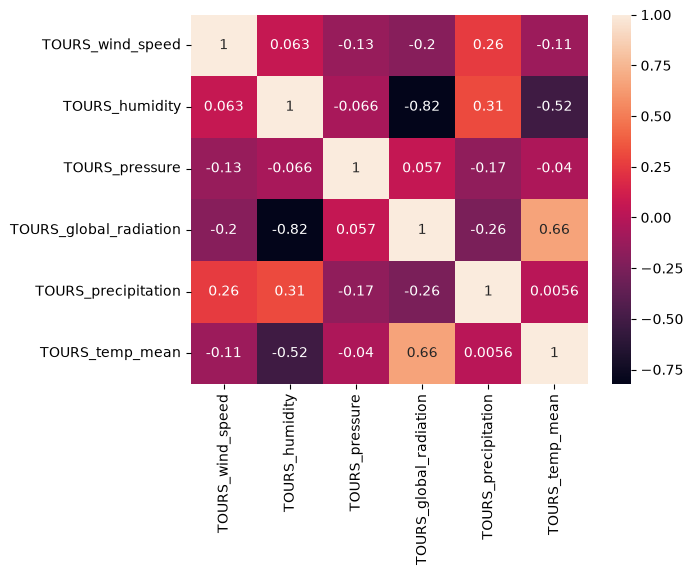

In [30]:
corr_df = df[['TOURS_wind_speed','TOURS_humidity','TOURS_pressure','TOURS_global_radiation','TOURS_precipitation',
            'TOURS_temp_mean']]

corr = corr_df.corr()

sns.heatmap(corr, annot=True)

## Modelling

Setting the date as index of the dataframe that will be used for ML purposes.

In [31]:
df_model = df.sort_values("DATE").set_index("DATE").copy()

Creating lag features, values of 1,3 and 7 previous days, and performing cyclical encoding of date, so that the starting months and ending months of an year are treated as neigbours.

In [32]:
for lag in [1,3,7]:
    df_model[f"temp_lag_{lag}"] = df_model["TOURS_temp_mean"].shift(lag)

In [33]:
df_model["humidity_lag"] = df_model["TOURS_humidity"].shift(1)
df_model["global_radiation_lag"] = df_model["TOURS_global_radiation"].shift(1)
df_model["precipitation_lag"] = df_model["TOURS_precipitation"].shift(1)
df_model["wind_speed_lag"] = df_model["TOURS_wind_speed"].shift(1)

In [34]:
dateofyear = df_model.index.dayofyear

df_model["dateofyear_sin"] = np.sin(2 * np.pi * dateofyear / 365.25)
df_model["dateofyear_cos"] = np.cos(2 * np.pi * dateofyear / 365.25)

In [35]:
df_model = df_model.dropna()

Splitting the data into test and train sets, and selecting the features and target variable for model.

In [36]:
features = ["temp_lag_1","temp_lag_3","temp_lag_7","humidity_lag","global_radiation_lag","precipitation_lag",
            "wind_speed_lag","dateofyear_sin","dateofyear_cos"]

target = ["TOURS_temp_mean"]

Setting the time period of 2000-2007 as training period, and from 2007-2009 as testing period.

In [37]:
train = df_model[df_model.index < "2007-01-01"]
test = df_model[df_model.index >= "2007-01-01"]

In [38]:
x_train, y_train = train[features], train[target]
x_test, y_test = test[features], test[target]

We will be using Ridge, GradientBoostingRegressor and Random Forest, and fit them simultaneously on the training data.

In [39]:
models = {
    "Ridge" : Ridge(alpha=1.0),
    "GradientBoostingRegressor" : GradientBoostingRegressor(random_state=42),
    "Random Forest" : RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
}

In [40]:
for model in models.values():
    model.fit(x_train, y_train)

## Model Evaluation

Adding new feature Persistence as baseline. 

In [41]:
df_model["Persistence"] = df_model["temp_lag_1"]

In [42]:
results = {}
results["Persistence"] = df_model.loc[test.index, "Persistence"]

In [43]:
for model_name, model in models.items():
    results[model_name] = model.predict(x_test)


In [44]:
metrics = pd.DataFrame({
    name : {"MAE" : mean_absolute_error(y_test, mo),
            "RMSE" : np.sqrt(mean_squared_error(y_test, mo))
            }
    for name,mo in results.items()        
}).T

In [45]:
metrics["MAE gain vs persistence (%)"] = (
    (metrics.loc["Persistence", "MAE"] - metrics["MAE"]) / metrics.loc["Persistence", "MAE"] * 100
)

In [46]:
print(metrics)

                                MAE      RMSE  MAE gain vs persistence (%)
Persistence                1.730201  2.180519                     0.000000
Ridge                      1.631402  2.039718                     5.710250
GradientBoostingRegressor  1.573343  1.976297                     9.065880
Random Forest              1.632009  2.047500                     5.675157


Taking user input to predict weather:, and compare different the prediction of different models.

In [48]:
target = "TOURS_temp_mean" 

date_input = input("Enter Date (YYYY-MM-DD) from 2001-2009")
date_input = pd.Timestamp(date_input)
print(f"Date: {date_input}")

if date_input not in df_model.index:
    print("Date not in range. Enter another date")

else:
    input_row = df_model.loc[[date_input]]
    original_data = input_row[target].iloc[0]

    pred_table = pd.DataFrame({
        "Model" : ["Original","Persistence"] + list(models.keys()),
        "Temperature" : [original_data, input_row["Persistence"].iloc[0]] + [m.predict(input_row[features])[0] for m in models.values()]})

    display(pred_table)


Date: 2004-03-21 00:00:00


,Model,Temperature
0,Original,10.700000
1,Persistence,12.400000
2,Ridge,10.603458
3,GradientBoostingRegressor,11.584141
4,Random Forest,10.997000
